# NIST TraCR Dataset — Exploratory Data Analysis

## Dataset Information

This notebook explores the NIST Tracking Community Resilience (TraCR) dataset to evaluate its structure, completeness, geographic coverage, and potential usefulness for community resilience research.

The dataset is already included in this repository under `datasets/TraCR_v1_database.csv`, so no additional download is required.

**Optional:** The original dataset can also be downloaded from the [NIST TraCR official website](https://data.nist.gov/od/id/mds2-3978).


## 1. Setup and load the official TraCR CSV

In [39]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

# Dataset source:
# https://data.nist.gov/od/id/mds2-3978
#
# The CSV is included in the repository.
# Downloading it separately is optional.

csv_path = Path("datasets") / "TraCR_v1_database.csv"

df = pd.read_csv(csv_path)

print("Dataset shape:", df.shape)
display(df.head())



FileNotFoundError: [Errno 2] No such file or directory: 'datasets/TraCR_v1_database.csv'

## 2. Structure, temporal coverage, and indicator categories

In [7]:
print("Unique geographic identifiers:", df["fips"].nunique())
print("Periods:", sorted(df["period"].dropna().unique()))
display(df.groupby("period")["fips"].nunique().rename("Geographic areas"))
print("Duplicate county-period rows:", df.duplicated(subset=["fips", "period"]).sum())


Unique geographic identifiers: 8157
Periods: [2000, 2001, 2002, 2003, 2004, 2005, 2006, 2007, 2008, 2009, 2010, 2011, 2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021]


period
2000    3938
2001    4133
2002    6090
2003    4303
2004    4491
2005    4535
2006    3993
2007    5961
2008    4149
2009    3943
2010    3903
2011    4233
2012    6092
2013    3935
2014    3797
2015    3798
2016    3766
2017    3276
2018    3234
2019    3234
2020    3234
2021    3234
Name: Geographic areas, dtype: int64

Duplicate county-period rows: 0


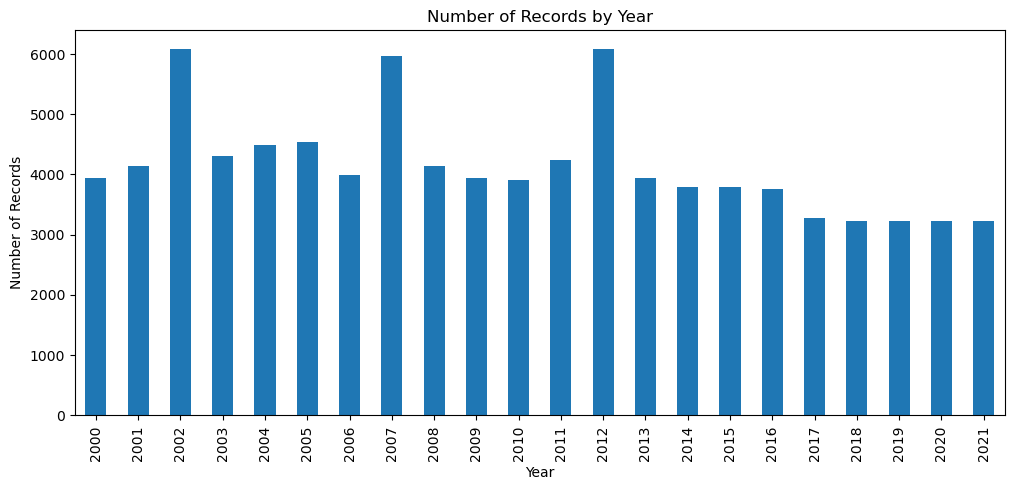

In [9]:
df['period'].value_counts().sort_index().plot(kind='bar', figsize=(12,5))

plt.title("Number of Records by Year")
plt.xlabel("Year")
plt.ylabel("Number of Records")
plt.show()

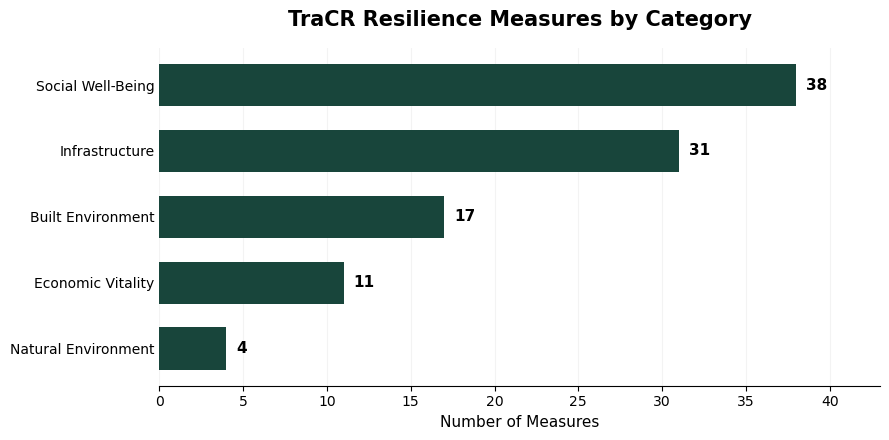

In [11]:
from pathlib import Path
Path("figures").mkdir(exist_ok=True)

# Group TraCR measures by category
categories = {
    "Infrastructure": [c for c in df.columns if c.startswith("INFRA")],
    "Social Well-Being": [c for c in df.columns if c.startswith("SOCWB")],
    "Built Environment": [c for c in df.columns if c.startswith("BLTENV")],
    "Economic Vitality": [c for c in df.columns if c.startswith("ECNVIT")],
    "Natural Environment": [c for c in df.columns if c.startswith("NATENV")]
}

category_counts = pd.Series({
    category: len(columns)
    for category, columns in categories.items()
}).sort_values()

# MSU green
msu_green = "#18453B"

fig, ax = plt.subplots(figsize=(9, 4.5))

bars = ax.barh(
    category_counts.index,
    category_counts.values,
    color=msu_green,
    height=0.65
)

# Add values at the end of each bar
for bar in bars:
    width = bar.get_width()
    ax.text(
        width + 0.6,
        bar.get_y() + bar.get_height() / 2,
        f"{int(width)}",
        va="center",
        fontsize=11,
        fontweight="bold"
    )

ax.set_title(
    "TraCR Resilience Measures by Category",
    fontsize=15,
    fontweight="bold",
    pad=16
)

ax.set_xlabel("Number of Measures", fontsize=11)
ax.set_xlim(0, category_counts.max() + 5)

# Clean presentation styling
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)
ax.tick_params(axis="y", length=0)
ax.grid(axis="x", alpha=0.15)
ax.set_axisbelow(True)

plt.tight_layout()
plt.savefig("figures/TraCR_Category_MSU.png", dpi=300, bbox_inches="tight")
plt.show()

## 3. Overall data completeness

In [14]:
missing_summary = pd.DataFrame({
    'Missing': df.isna().sum(),
    'Available': df.notna().sum(),
    'Percent Missing': df.isna().mean() * 100,
    'Percent Available': df.notna().mean() * 100
})

missing_summary.sort_values('Percent Available', ascending=False)

,Missing,Available,Percent Missing,Percent Available
UID,0,91272,0.000000,100.000000
period,0,91272,0.000000,100.000000
fips,0,91272,0.000000,100.000000
ECNVIT510001,36569,54703,40.065957,59.934043
SOCWB310015,37286,53986,40.851521,59.148479
...,...,...,...,...
INFRA150017,88648,2624,97.125077,2.874923
INFRA130002,90517,755,99.172802,0.827198
SOCWB350003,90944,328,99.640635,0.359365
SOCWB350002,90944,328,99.640635,0.359365


Measures: 101
Overall observed cells (%): 14.07
Measures entirely missing: 0
Measures with >=80% coverage: 0


,Coverage (%)
count,101.000000
mean,14.072896
std,17.166519
min,0.359365
25%,3.593654
50%,7.056929
75%,10.681260
max,59.934043


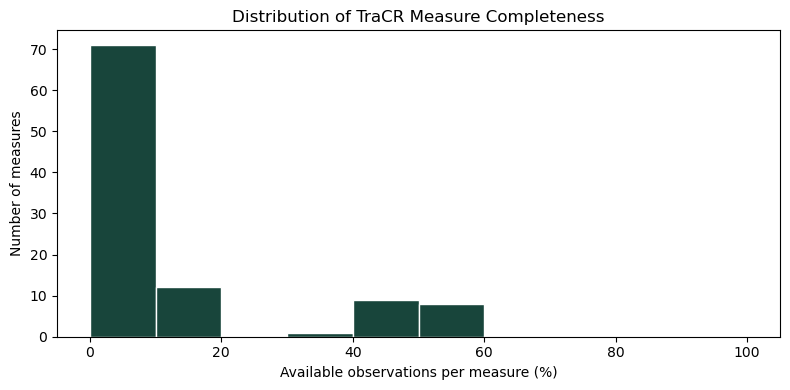

In [16]:
# Exclude identifiers and period from measures when assessing completeness.
measure_cols = [c for c in df.columns if c not in ["UID", "fips", "period"]]
coverage_all = df[measure_cols].notna().mean().mul(100)
print("Measures:", len(measure_cols))
print("Overall observed cells (%):", round(df[measure_cols].notna().to_numpy().mean() * 100, 2))
print("Measures entirely missing:", int((coverage_all == 0).sum()))
print("Measures with >=80% coverage:", int((coverage_all >= 80).sum()))
display(coverage_all.describe().rename("Coverage (%)").to_frame())

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(coverage_all, bins=np.linspace(0, 100, 11), color="#18453B", edgecolor="white")
ax.set(title="Distribution of TraCR Measure Completeness", xlabel="Available observations per measure (%)", ylabel="Number of measures")
plt.tight_layout()
plt.show()


### Completeness by period

,Available measure cells (%)
period,
2000,6.353177
2001,9.111163
2002,4.108179
2003,5.814272
2004,5.570878
2005,8.939273
2006,13.470603
2007,6.973712
2008,10.031524


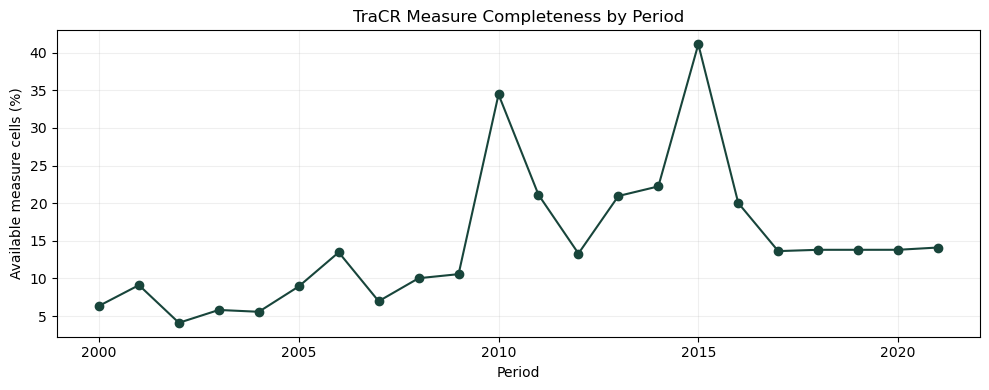

In [19]:
period_coverage = df.groupby("period")[measure_cols].apply(lambda x: x.notna().to_numpy().mean() * 100)
display(period_coverage.rename("Available measure cells (%)").to_frame())
period_coverage.plot(marker="o", figsize=(10, 4), color="#18453B")
plt.title("TraCR Measure Completeness by Period")
plt.ylabel("Available measure cells (%)")
plt.xlabel("Period")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()


## 4. Florida and Orange County pilot

Orange County (FIPS `12095`) is used as a county-level geographic pilot relevant to Orlando. TraCR observations are county-level; they should not be described as city-specific measurements.

In [22]:
df["fips_clean"] = df["fips"].astype("string").str.replace(r"\.0$", "", regex=True).str.zfill(5)
florida = df[df["fips_clean"].str.startswith("12", na=False)].copy()
orange = df[df["fips_clean"] == "12095"].copy()
print("Florida rows:", len(florida), "| Orange County rows:", len(orange))
print("Orange County periods:", sorted(orange["period"].dropna().unique()))
if orange.empty:
    raise ValueError("No Orange County observations found. Check FIPS formatting and dataset version.")


Florida rows: 1797 | Orange County rows: 22
Orange County periods: [2000, 2001, 2002, 2003, 2004, 2005, 2006, 2007, 2008, 2009, 2010, 2011, 2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021]


In [24]:
measure_cols = [
    col for col in df.columns
    if col not in ["UID", "fips", "fips_clean", "period"]
]

orange_coverage = orange[measure_cols].notna().mean() * 100

print("Total TraCR measures:", len(measure_cols))
print("Measures with ANY Orange County data:",
      (orange_coverage > 0).sum())

print("Measures with >= 50% coverage:",
      (orange_coverage >= 50).sum())

print("Measures with 100% coverage:",
      (orange_coverage == 100).sum())

orange_coverage.sort_values(ascending=False).head(20)

Total TraCR measures: 101
Measures with ANY Orange County data: 101
Measures with >= 50% coverage: 47
Measures with 100% coverage: 0


ECNVIT510001    77.272727
SOCWB310017     77.272727
SOCWB310015     77.272727
SOCWB320019     77.272727
SOCWB320018     77.272727
SOCWB320013     77.272727
SOCWB320017     77.272727
SOCWB320016     77.272727
BLTENV220006    54.545455
BLTENV220001    54.545455
BLTENV220002    54.545455
BLTENV220003    54.545455
BLTENV220004    54.545455
BLTENV220005    54.545455
INFRA120005     54.545455
BLTENV220007    54.545455
ECNVIT530001    54.545455
INFRA120006     54.545455
INFRA120008     54.545455
BLTENV220008    54.545455
dtype: float64

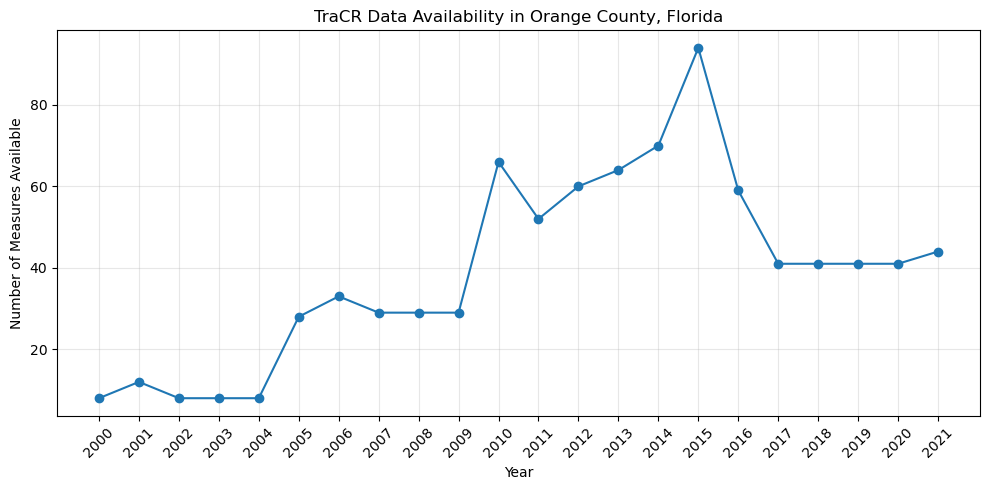

In [26]:
year_coverage = orange.set_index("period")[measure_cols].notna().sum(axis=1)

import matplotlib.pyplot as plt

plt.figure(figsize=(10,5))

plt.plot(
    year_coverage.index,
    year_coverage.values,
    marker="o"
)

plt.xlabel("Year")
plt.ylabel("Number of Measures Available")
plt.title("TraCR Data Availability in Orange County, Florida")
plt.xticks(year_coverage.index, rotation=45)
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

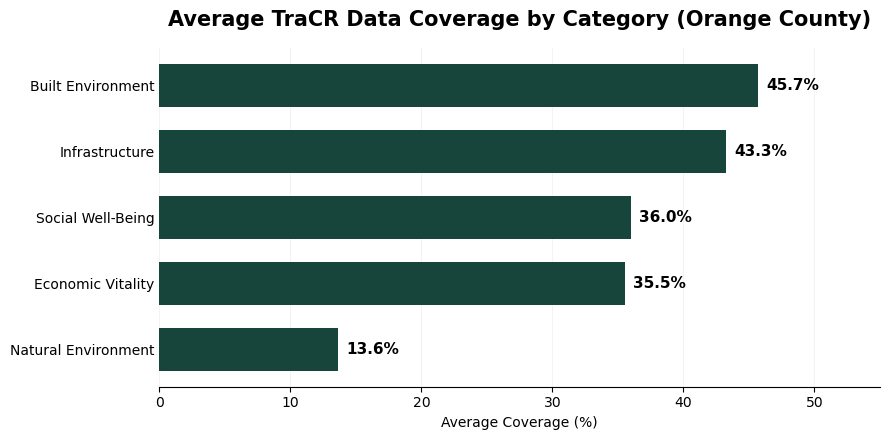

In [28]:
from pathlib import Path
Path("figures").mkdir(exist_ok=True)

categories = {
    "Infrastructure": "INFRA",
    "Social Well-Being": "SOCWB",
    "Built Environment": "BLTENV",
    "Economic Vitality": "ECNVIT",
    "Natural Environment": "NATENV"
}

coverage = {}

for category, prefix in categories.items():
    cols = [c for c in measure_cols if c.startswith(prefix)]
    coverage[category] = orange[cols].notna().mean().mean() * 100

coverage = pd.Series(coverage).sort_values()

fig, ax = plt.subplots(figsize=(9, 4.5))

bars = ax.barh(
    coverage.index,
    coverage.values,
    color="#18453B",
    height=0.65
)

for bar in bars:
    ax.text(
        bar.get_width() + 0.6,
        bar.get_y() + bar.get_height() / 2,
        f"{bar.get_width():.1f}%",
        va="center",
        fontsize=11,
        fontweight="bold"
    )

ax.set_title(
    "Average TraCR Data Coverage by Category (Orange County)",
    fontsize=15,
    fontweight="bold",
    pad=16
)
ax.set_xlabel("Average Coverage (%)")
ax.set_xlim(0, 55)
ax.grid(axis="x", alpha=0.15)
ax.set_axisbelow(True)

for spine in ["top", "right", "left"]:
    ax.spines[spine].set_visible(False)

ax.tick_params(axis="y", length=0)

plt.tight_layout()
plt.savefig("figures/TraCR_Coverage_MSU.png", dpi=300, bbox_inches="tight")
plt.show()

## 5. Additional pilot comparison: Orange County vs. Florida

In [31]:
# Compare completeness, not resilience outcomes.
florida_coverage = florida[measure_cols].notna().mean().mul(100)
comparison = pd.DataFrame({
    "Orange County (%)": orange[measure_cols].notna().mean().mul(100),
    "Florida (%)": florida_coverage
})
comparison["Difference (percentage points)"] = comparison["Orange County (%)"] - comparison["Florida (%)"]
display(comparison.sort_values("Difference (percentage points)").head(10))
print("Mean Orange County measure coverage (%):", round(comparison["Orange County (%)"].mean(), 1))
print("Mean Florida measure coverage (%):", round(comparison["Florida (%)"].mean(), 1))


,Orange County (%),Florida (%),Difference (percentage points)
SOCWB350003,4.545455,3.728436,0.817018
SOCWB350002,4.545455,3.728436,0.817018
SOCWB350001,4.545455,3.728436,0.817018
SOCWB330013,4.545455,3.728436,0.817018
SOCWB330011,4.545455,3.728436,0.817018
SOCWB350007,4.545455,3.728436,0.817018
INFRA130002,4.545455,3.450195,1.095260
SOCWB310006,9.090909,7.456873,1.634037
ECNVIT530004,9.090909,7.456873,1.634037
BLTENV220018,9.090909,7.456873,1.634037


Mean Orange County measure coverage (%): 38.9
Mean Florida measure coverage (%): 28.2


### Coverage by resilience category: Orange County vs. Florida

,Orange County,Florida
Infrastructure,43.3,35.4
Social Well-Being,36.0,23.4
Built Environment,45.7,34.6
Economic Vitality,35.5,20.8
Natural Environment,13.6,11.2


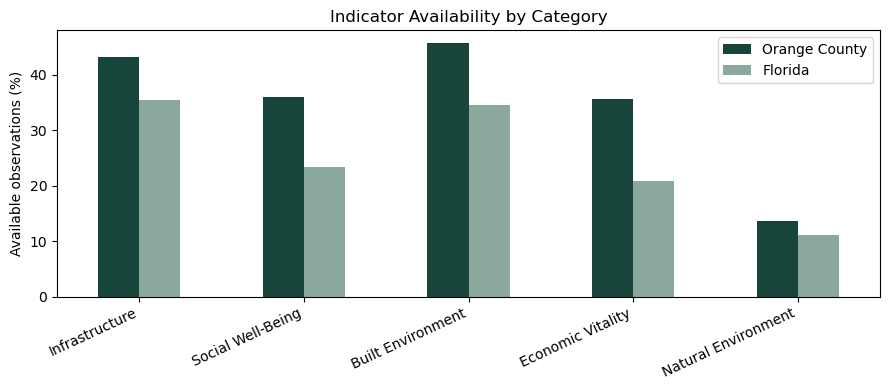

In [34]:
prefixes = {
    "Infrastructure": "INFRA",
    "Social Well-Being": "SOCWB",
    "Built Environment": "BLTENV",
    "Economic Vitality": "ECNVIT",
    "Natural Environment": "NATENV",
}
category_comparison = pd.DataFrame({
    "Orange County": {name: orange[[c for c in measure_cols if c.startswith(prefix)]].notna().to_numpy().mean() * 100 if any(c.startswith(prefix) for c in measure_cols) else np.nan for name, prefix in prefixes.items()},
    "Florida": {name: florida[[c for c in measure_cols if c.startswith(prefix)]].notna().to_numpy().mean() * 100 if any(c.startswith(prefix) for c in measure_cols) else np.nan for name, prefix in prefixes.items()}
})
display(category_comparison.round(1))
category_comparison.plot.bar(figsize=(9, 4), color=["#18453B", "#8BA89C"])
plt.title("Indicator Availability by Category")
plt.ylabel("Available observations (%)")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()


## 6. Findings, limitations, and next steps

- **What this analysis evaluates:** TraCR's coverage across counties, periods, indicator groups, and an Orange County pilot.
- **Data challenges:** Missing measures and coded indicators complicate direct comparison. Interpret each measure using NIST's metadata and source definitions before modeling or drawing substantive conclusions.
- **Geographic limitation:** Orange County is a proxy geographic area for an Orlando-focused pilot, **not** a dataset of City of Orlando observations.
- **Project fit:** TraCR provides quantitative county-level resilience context, but it does **not** directly identify or download municipal resilience planning documents.
- **Next steps:** Select well-documented indicators with adequate completeness, review their units and definitions in the [official metadata](https://data.nist.gov/od/ds/mds2-3978/TraCR_Metadata.xlsx), and evaluate whether they can supplement the team's document-discovery workflow.

**Interpretation note:** The charts describe availability, not actual resilience performance. Review the executed outputs before adding specific numeric findings to the team's report.
